# Phase 1 · 좌표와 벡터란 무엇인가 📍

웹 챕터와 짝을 이루는 Python 실습입니다. 좌표평면 위에 점을 찍고, 사분면을 확인하고,
점을 벡터(화살표)로 그려봅니다.

준비물: `pip install -r requirements.txt`

> 🤖 **AI 튜터** — 아래 셀을 실행하면 웹앱처럼 화면 오른쪽 아래에 🤖 버튼이 생깁니다.
> 버튼을 누르면 채팅창이 열리고, 어디를 스크롤해도 그 자리에 떠 있어요. 막히면 언제든 질문하세요.
> (로컬 Ollama 필요 — 꺼져 있으면 켜는 방법이 안내되고, 튜터 없이도 학습에는 지장 없습니다.)

In [1]:
# 🤖 AI 튜터 — 실행하면 오른쪽 아래에 🤖 버튼이 떠요 (웹앱과 같은 로컬 AI, 클릭해서 열기)
from tutor import chat

chat('ch1')

## 1. 좌표평면에 점 찍기

순서쌍 `(x, y)` 는 가로 x, 세로 y 위치를 뜻합니다. 점 P(3, 2)를 찍어봅시다.

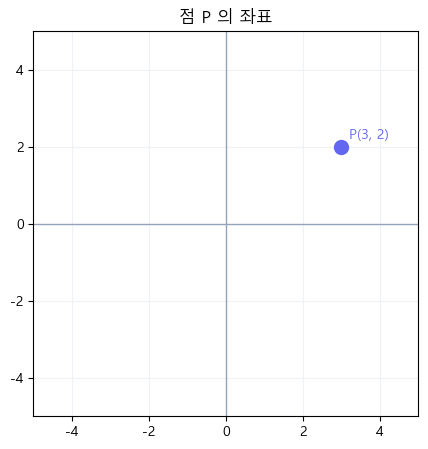

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 한글 폰트 설정 (안 하면 한글 제목/라벨이 네모로 깨짐)
# Windows: 'Malgun Gothic' / macOS: 'AppleGothic' / Linux: 'NanumGothic' 로 바꾸세요
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False  # 음수 부호(-) 깨짐 방지

def setup_plane(ax, r=5):
    """좌표평면 기본 꾸미기: 축, 격자, 정사각 비율"""
    ax.set_xlim(-r, r); ax.set_ylim(-r, r)
    ax.axhline(0, color='#94a3b8', lw=1)   # x축
    ax.axvline(0, color='#94a3b8', lw=1)   # y축
    ax.grid(True, color='#eef2f7')
    ax.set_aspect('equal')

P = (3, 2)
fig, ax = plt.subplots(figsize=(5, 5))
setup_plane(ax)
ax.plot(P[0], P[1], 'o', color='#6366f1', markersize=10)
ax.text(P[0] + 0.2, P[1] + 0.2, f'P{P}', color='#6366f1')
ax.set_title('점 P 의 좌표')
plt.show()

**순서가 중요!** `(3, 2)` 와 `(2, 3)` 은 다른 점입니다. 직접 비교해 보세요.

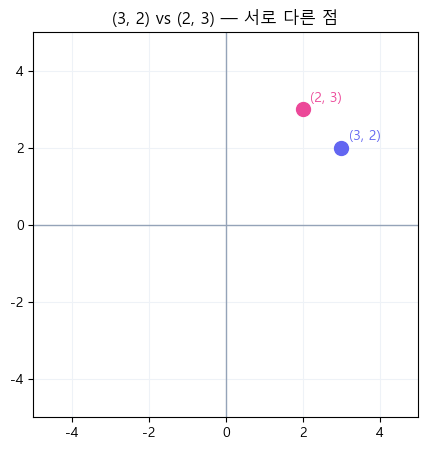

In [3]:
fig, ax = plt.subplots(figsize=(5, 5))
setup_plane(ax)
for pt, c in [((3, 2), '#6366f1'), ((2, 3), '#ec4899')]:
    ax.plot(pt[0], pt[1], 'o', color=c, markersize=10)
    ax.text(pt[0] + 0.2, pt[1] + 0.2, str(pt), color=c)
ax.set_title('(3, 2) vs (2, 3) — 서로 다른 점')
plt.show()

## 2. 사분면 확인하기

x, y의 부호로 사분면이 정해집니다. 네 점을 찍어 한눈에 봅시다.

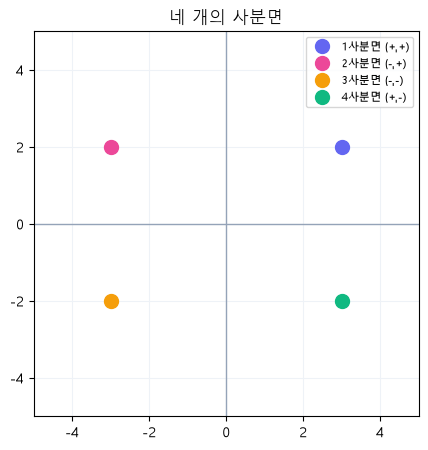

(-4, 1) 은 2 사분면


In [3]:
points = {
    '1사분면 (+,+)': (3, 2),
    '2사분면 (-,+)': (-3, 2),
    '3사분면 (-,-)': (-3, -2),
    '4사분면 (+,-)': (3, -2),
}
colors = ['#6366f1', '#ec4899', '#f59e0b', '#10b981']

fig, ax = plt.subplots(figsize=(5, 5))
setup_plane(ax)
for (label, (x, y)), c in zip(points.items(), colors):
    ax.plot(x, y, 'o', color=c, markersize=10, label=label)
ax.legend(loc='upper right', fontsize=8)
ax.set_title('네 개의 사분면')
plt.show()

def quadrant(x, y):
    if x > 0 and y > 0: return 1
    if x < 0 and y > 0: return 2
    if x < 0 and y < 0: return 3
    if x > 0 and y < 0: return 4
    return 0  # 축 위

print('(-4, 1) 은', quadrant(-4, 1), '사분면')

## 3. 점을 벡터(화살표)로 그리기

원점에서 점까지 화살표를 그으면 벡터입니다. NumPy 배열로 벡터를 만들고 `quiver` 로 그립니다.

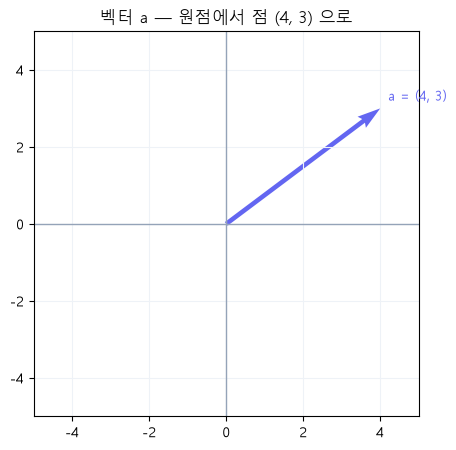

x성분: 4 , y성분: 3


In [4]:
a = np.array([4, 3])   # 벡터 a = (4, 3)

fig, ax = plt.subplots(figsize=(5, 5))
setup_plane(ax)
ax.quiver(0, 0, a[0], a[1], angles='xy', scale_units='xy', scale=1, color='#6366f1', width=0.012)
ax.text(a[0] + 0.2, a[1] + 0.2, f'a = ({a[0]}, {a[1]})', color='#6366f1')
ax.set_title('벡터 a — 원점에서 점 (4, 3) 으로')
plt.show()

print('x성분:', a[0], ', y성분:', a[1])

## 4. 직접 풀어보기 ✏️

점 `(-2, -5)` 가 몇 사분면인지 위에서 만든 `quadrant` 함수로 확인해 보세요. (정답: 3)

In [5]:
# TODO: quadrant(-2, -5) 를 출력해 보세요.
ans = quadrant(-2, -5)
print('정답:', ans, '사분면')
assert ans == 3, '다시 확인해 보세요!'
print('✅ 맞아요! x<0, y<0 이라 3사분면.')

정답: 3 사분면
✅ 맞아요! x<0, y<0 이라 3사분면.


---
다음 챕터: **벡터 연산** — 벡터를 더하고, 빼고, 늘여봅니다. 🙂